## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.00334ms.
00: Found the following number of samples per ticker: SPX: 2616.
00: Found date range 2015-01-02 to 2025-07-01 with 2616 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2078 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.37s.
/done


## AEC

Cleaning up memory... done.
['ask_vol', 'bdte', 'bid_vol', 'call_ask', 'call_bid', 'call_opt_id', 'df', 'expiry_id', 'fit1_vol', 'fitX_vol', 'fwd', 'fwd_ref', 'is_am', 'is_american', 'is_valid', 'log_open_interest', 'log_volume', 'mask_arb_free', 'mkt_call_ask', 'mkt_call_bid', 'mkt_call_log_open_interest', 'mkt_call_log_volume', 'mkt_put_ask', 'mkt_put_bid', 'mkt_put_log_open_interest', 'mkt_put_log_volume', 'nms', 'nms_atm', 'pure_ask_delta', 'pure_ask_dk', 'pure_ask_gamma', 'pure_ask_price', 'pure_ask_theta', 'pure_ask_vega', 'pure_bid_delta', 'pure_bid_dk', 'pure_bid_gamma', 'pure_bid_price', 'pure_bid_theta', 'pure_bid_vega', 'pure_fit1_delta', 'pure_fit1_dk', 'pure_fit1_gamma', 'pure_fit1_price', 'pure_fit1_theta', 'pure_fit1_vega', 'pure_fitX_delta', 'pure_fitX_dk', 'pure_fitX_gamma', 'pure_fitX_price', 'pure_fitX_theta', 'pure_fitX_vega', 'pure_strike', 'put_opt_id', 'spot_prev', 'spot_ref', 'spot_ret', 'strike', 'time_y', 'tte_y']
['ask_vol', 'bdte', 'bid_vol', 'call_ask', 'ca

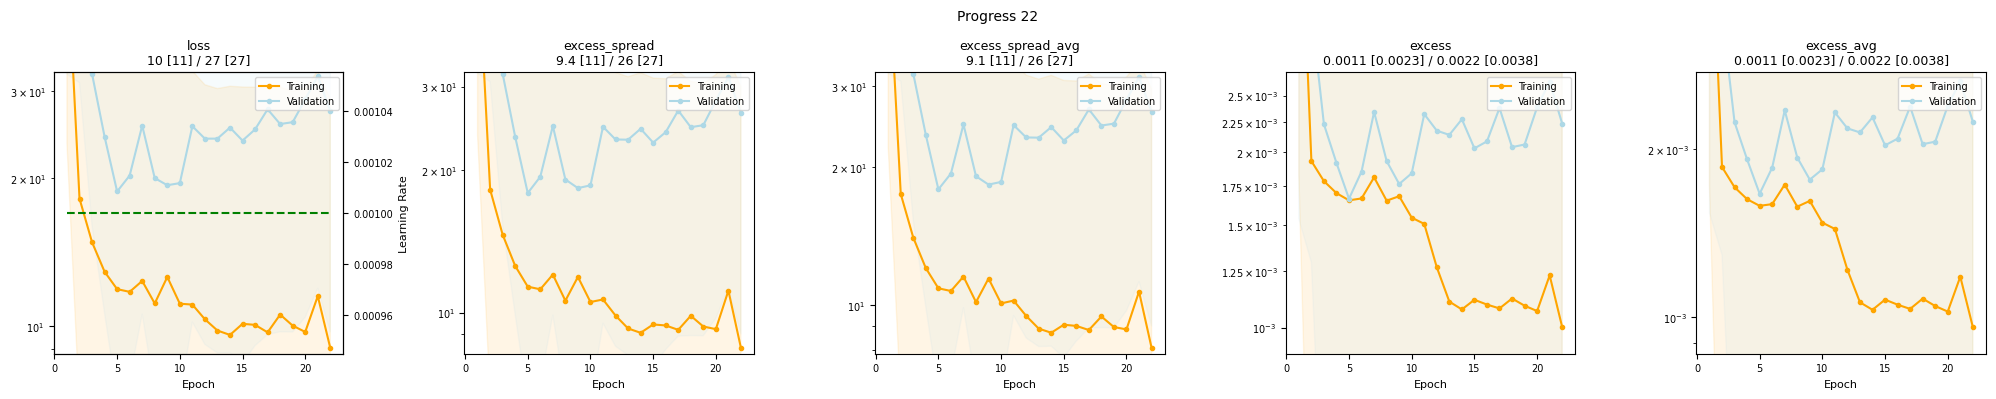

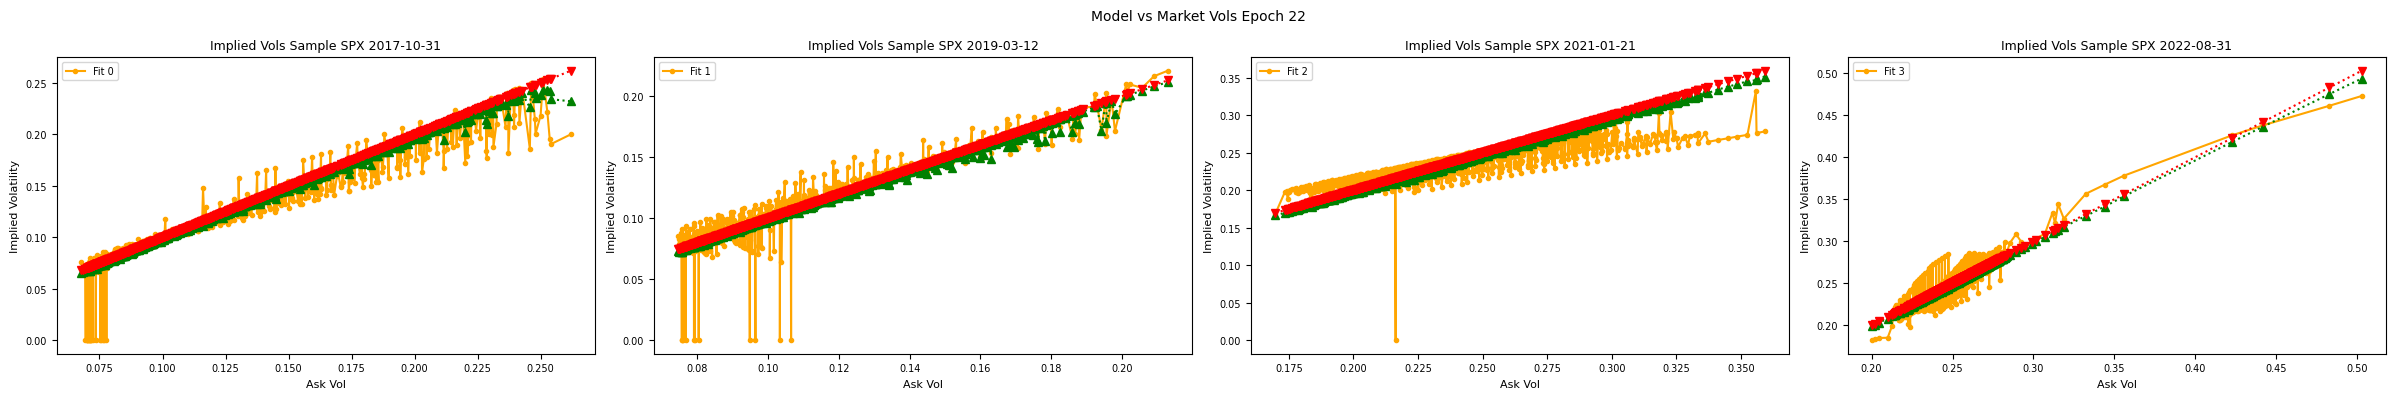

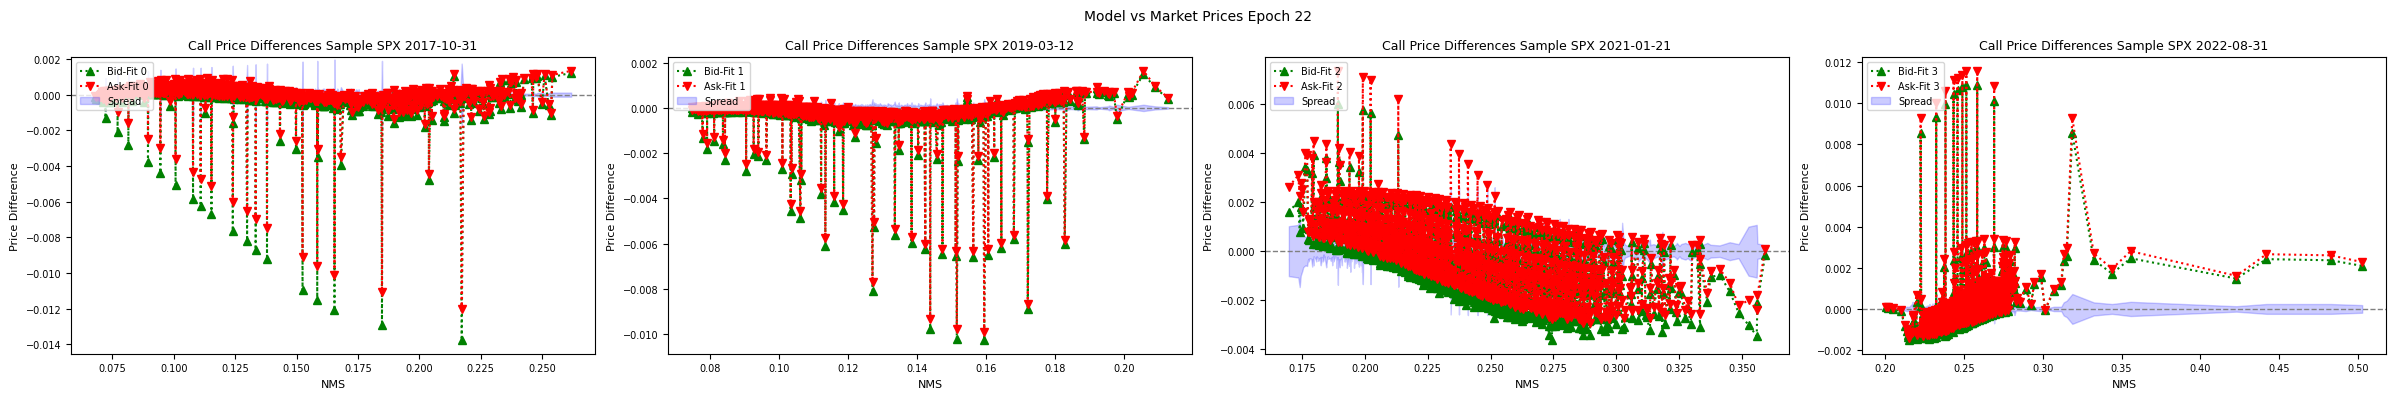

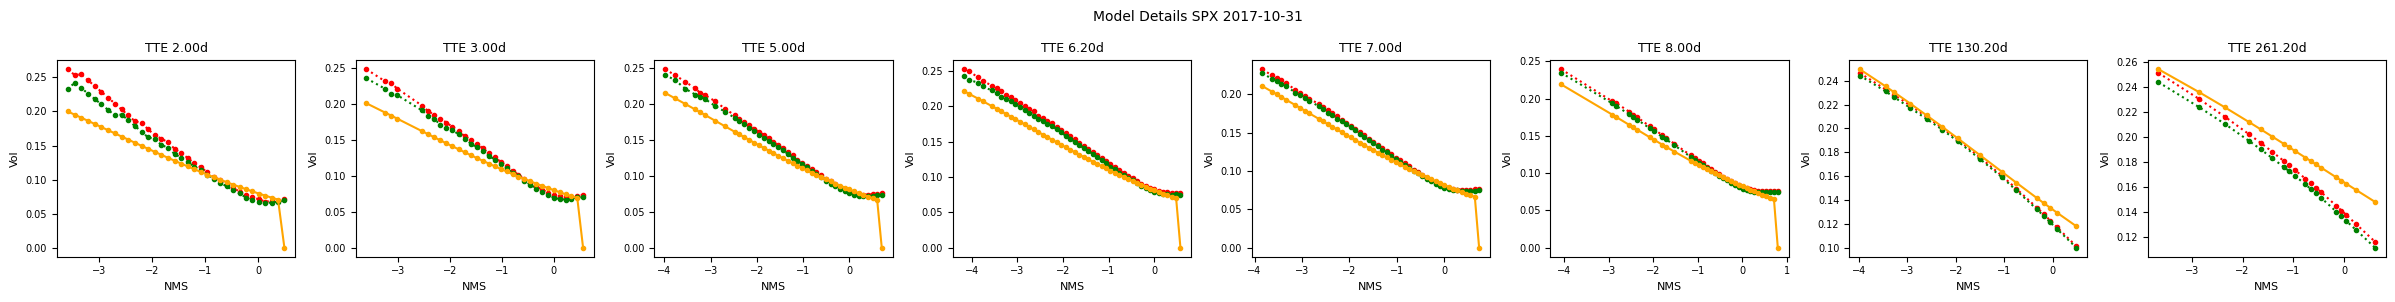

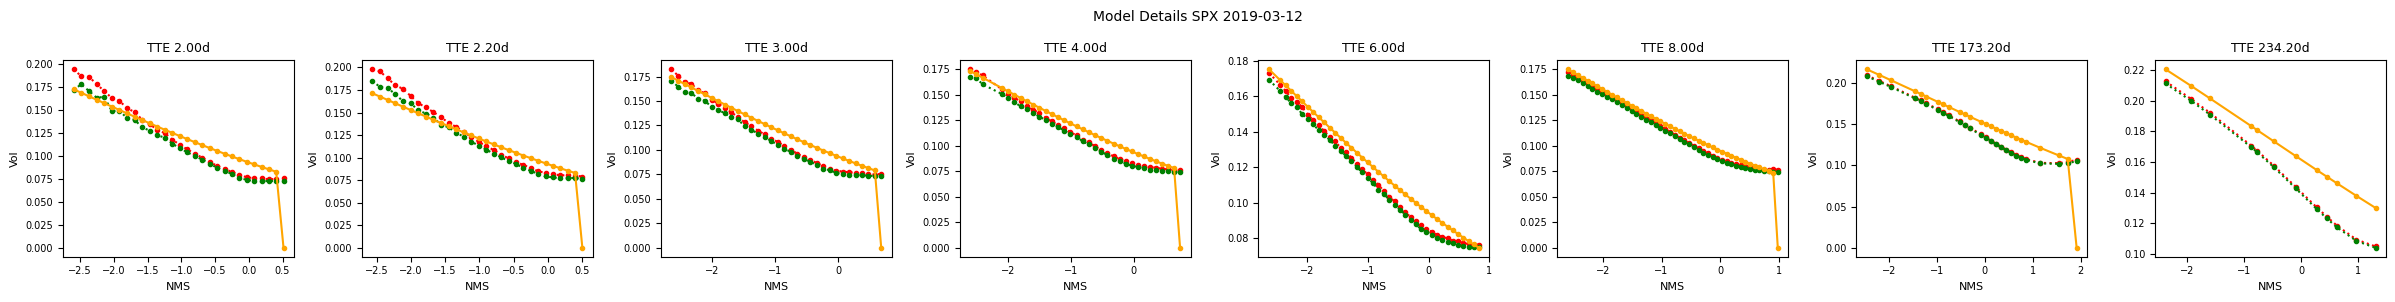

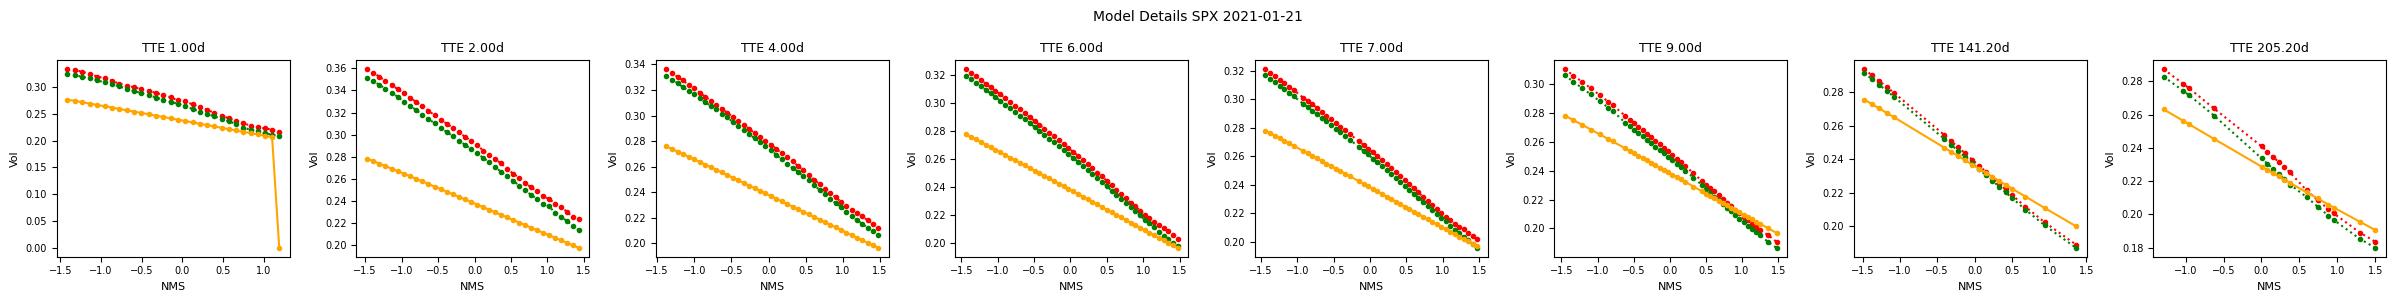

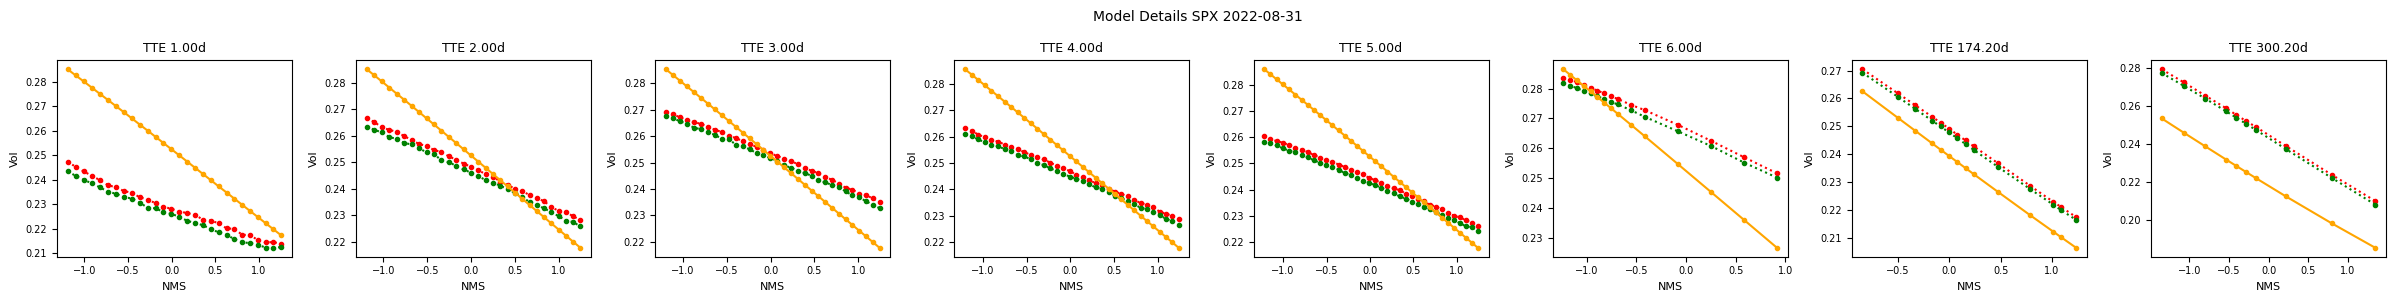

00: Training 'train_vol_vol_attin-big' epoch 2/1000 error avg trn 50.15; val 18.17/58.45 [2:36 1.4s 0.37s]. LR: 1.00e-03, GN 64.44, excess_weighted: 0.001165/0.002631, excess_weighted_avg: 0.001331/0.002686, excess_spread: 18.18/58.51, excess_spread_avg: 17.47/58.51, excess: 0.00193/0.003489, excess_avg: 0.001857/0.003488. ETA: 45:18:28.
01:   Epoch 2: Saving new best validation loss 58.45 vs. 68.21 at epoch 1 to '/media/storage/quantdata/experiments/dysanos/simple/32536c2da5702cb9/v1/train_vol_vol_attin-big 37aa408e/best.pt'... done; this took 0.011s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/32536c2da5702cb9/v1/train_vol_vol_attin-big 37aa408e/last.pt... done; this took 5.34ms.
00: Training 'train_vol_vol_attin-big' epoch 3/1000 error avg trn 18.04; val 14.82/32.53 [3:55 1.4s 0.37s]. LR: 1.00e-03, GN 17.75, excess_weighted: 0.000935/0.001435, excess_weighted_avg: 0.001115/0.00156, excess_spread: 14.6/31.91, excess_spread_avg: 14.03/31.92, excess: 

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 128,
    fit_average = True,

    encoder = AttentionPoolingEncoderFactory(
        num_head = 128,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 128,
            activation = 'Softplus',    
        )
    ),)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=128 )
